<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Space X  Falcon 9 First Stage Landing Prediction**


 ## Lab 2: Data wrangling


Estimated time needed: **60** minutes


In this lab, we will perform some Exploratory Data Analysis (EDA) to find some patterns in the data and determine what would be the label for training supervised models.

In the data set, there are several different cases where the booster did not land successfully. Sometimes a landing was attempted but failed due to an accident; for example, <code>True Ocean</code> means the mission outcome was successfully  landed to a specific region of the ocean while <code>False Ocean</code> means the mission outcome was unsuccessfully landed to a specific region of the ocean. <code>True RTLS</code> means the mission outcome was successfully  landed to a ground pad <code>False RTLS</code> means the mission outcome was unsuccessfully landed to a ground pad.<code>True ASDS</code> means the mission outcome was successfully landed on  a drone ship <code>False ASDS</code> means the mission outcome was unsuccessfully landed on a drone ship.

In this lab we will mainly convert those outcomes into Training Labels with `1` means the booster successfully landed `0` means it was unsuccessful.


Falcon 9 first stage will land successfully


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


## Objectives
Perform exploratory  Data Analysis and determine Training Labels

- Exploratory Data Analysis
- Determine Training Labels


----


Install the below libraries


In [ ]:
!pip install pandas
!pip install numpy

## Import Libraries and Define Auxiliary Functions


We will import the following libraries.


In [ ]:
# Pandas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
#NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np

### Data Analysis


Load Space X dataset, from last section.


In [ ]:
df=pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_1.csv")
df.head(10)

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857
5,6,2014-01-06,Falcon 9,3325.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1005,-80.577366,28.561857
6,7,2014-04-18,Falcon 9,2296.000000,ISS,CCAFS SLC 40,True Ocean,1,False,False,True,NaN,1.0,0,B1006,-80.577366,28.561857
7,8,2014-07-14,Falcon 9,1316.000000,LEO,CCAFS SLC 40,True Ocean,1,False,False,True,NaN,1.0,0,B1007,-80.577366,28.561857
8,9,2014-08-05,Falcon 9,4535.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1008,-80.577366,28.561857
9,10,2014-09-07,Falcon 9,4428.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1011,-80.577366,28.561857


Identify and calculate the percentage of the missing values in each attribute


In [ ]:
df.isnull().sum()/len(df)*100

,0
FlightNumber,0.000000
Date,0.000000
BoosterVersion,0.000000
PayloadMass,0.000000
Orbit,0.000000
LaunchSite,0.000000
Outcome,0.000000
Flights,0.000000
GridFins,0.000000
Reused,0.000000


Identify which columns are numerical and categorical:


In [ ]:
df.dtypes

,0
FlightNumber,int64
Date,object
BoosterVersion,object
PayloadMass,float64
Orbit,object
LaunchSite,object
Outcome,object
Flights,int64
GridFins,bool
Reused,bool


### TASK 1: Calculate the number of launches on each site

The data contains several Space X  launch facilities: <a href='https://en.wikipedia.org/wiki/List_of_Cape_Canaveral_and_Merritt_Island_launch_sites'>Cape Canaveral Space</a> Launch Complex 40  <b>VAFB SLC 4E </b> , Vandenberg Air Force Base Space Launch Complex 4E <b>(SLC-4E)</b>, Kennedy Space Center Launch Complex 39A <b>KSC LC 39A </b>.The location of each Launch Is placed in the column <code>LaunchSite</code>


Next, let's see the number of launches for each site.

Use the method  <code>value_counts()</code> on the column <code>LaunchSite</code> to determine the number of launches  on each site:


In [ ]:
df['LaunchSite'].value_counts()

,count
LaunchSite,
CCAFS SLC 40,55
KSC LC 39A,22
VAFB SLC 4E,13


Each launch aims to an dedicated orbit, and here are some common orbit types:




* <b>LEO</b>: Low Earth orbit (LEO)is an Earth-centred orbit with an altitude of 2,000 km (1,200 mi) or less (approximately one-third of the radius of Earth),[1] or with at least 11.25 periods per day (an orbital period of 128 minutes or less) and an eccentricity less than 0.25.[2] Most of the manmade objects in outer space are in LEO <a href='https://en.wikipedia.org/wiki/Low_Earth_orbit'>[1]</a>.

* <b>VLEO</b>: Very Low Earth Orbits (VLEO) can be defined as the orbits with a mean altitude below 450 km. Operating in these orbits can provide a number of benefits to Earth observation spacecraft as the spacecraft operates closer to the observation<a href='https://www.researchgate.net/publication/271499606_Very_Low_Earth_Orbit_mission_concepts_for_Earth_Observation_Benefits_and_challenges'>[2]</a>.


* <b>GTO</b>(Geostationary Transfer Orbit): A geostationary transfer orbit is an elliptical Earth orbit used to transfer satellites from low Earth orbit (LEO) to geostationary orbit (GEO). In a GTO, the perigee (closest point to Earth) is much lower than GEO altitude, while the apogee (farthest point) reaches approximately 22,236 miles (35,786 kilometers) above Earth’s equator — the altitude of a geostationary orbit. Satellites in GTO use onboard propulsion to circularize their orbit at GEO altitude, where they can provide services such as weather monitoring, communications, and surveillance. <a  href="https://www.space.com/29222-geosynchronous-orbit.html" >[3] </a>.


* <b>SSO (or SO)</b>: It is a Sun-synchronous orbit  also called a heliosynchronous orbit is a nearly polar orbit around a planet, in which the satellite passes over any given point of the planet's surface at the same local mean solar time <a href="https://en.wikipedia.org/wiki/Sun-synchronous_orbit">[4] <a>.
    
    
    
* <b>ES-L1 </b>:At the Lagrange points the gravitational forces of the two large bodies cancel out in such a way that a small object placed in orbit there is in equilibrium relative to the center of mass of the large bodies. L1 is one such point between the sun and the earth <a href="https://en.wikipedia.org/wiki/Lagrange_point#L1_point">[5]</a> .
    
    
* <b>HEO</b> A highly elliptical orbit, is an elliptic orbit with high eccentricity, usually referring to one around Earth <a href="https://en.wikipedia.org/wiki/Highly_elliptical_orbit">[6]</a>.


* <b> ISS </b> A modular space station (habitable artificial satellite) in low Earth orbit. It is a multinational collaborative project between five participating space agencies: NASA (United States), Roscosmos (Russia), JAXA (Japan), ESA (Europe), and CSA (Canada)<a href="https://en.wikipedia.org/wiki/International_Space_Station"> [7] </a>


* <b> MEO </b> Geocentric orbits ranging in altitude from 2,000 km (1,200 mi) to just below geosynchronous orbit at 35,786 kilometers (22,236 mi). Also known as an intermediate circular orbit. These are "most commonly at 20,200 kilometers (12,600 mi), or 20,650 kilometers (12,830 mi), with an orbital period of 12 hours <a href="https://en.wikipedia.org/wiki/List_of_orbits"> [8] </a>


* <b> HEO </b> Geocentric orbits above the altitude of geosynchronous orbit (35,786 km or 22,236 mi) <a href="https://en.wikipedia.org/wiki/List_of_orbits"> [9] </a>


* <b> GEO </b> It is a circular geosynchronous orbit 35,786 kilometres (22,236 miles) above Earth's equator and following the direction of Earth's rotation <a href="https://en.wikipedia.org/wiki/Geostationary_orbit"> [10] </a>


* <b> PO </b> It is one type of satellites in which a satellite passes above or nearly above both poles of the body being orbited (usually a planet such as the Earth <a href="https://en.wikipedia.org/wiki/Polar_orbit"> [11] </a>

some are shown in the following plot:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/Orbits.png)


### TASK 2: Calculate the number and occurrence of each orbit


 Use the method  <code>.value_counts()</code> to determine the number and occurrence of each orbit in the  column <code>Orbit</code>


Note: Do not count GTO, as it is a transfer orbit and not itself geostationary.


In [ ]:
df['Orbit'].value_counts()

,count
Orbit,
GTO,27
ISS,21
VLEO,14
PO,9
LEO,7
SSO,5
MEO,3
HEO,1
ES-L1,1


### TASK 3: Calculate the number and occurence of mission outcome of the orbits


Use the method <code>.value_counts()</code> on the column <code>Outcome</code> to determine the number of <code>landing_outcomes</code>.Then assign it to a variable landing_outcomes.


In [ ]:
landing_outcomes = df['Outcome'].value_counts()
landing_outcomes

,count
Outcome,
True ASDS,41
None None,19
True RTLS,14
False ASDS,6
True Ocean,5
False Ocean,2
None ASDS,2
False RTLS,1


<code>True Ocean</code> means the mission outcome was successfully  landed to a specific region of the ocean while <code>False Ocean</code> means the mission outcome was unsuccessfully landed to a specific region of the ocean. <code>True RTLS</code> means the mission outcome was successfully  landed to a ground pad <code>False RTLS</code> means the mission outcome was unsuccessfully landed to a ground pad.<code>True ASDS</code> means the mission outcome was successfully  landed to a drone ship <code>False ASDS</code> means the mission outcome was unsuccessfully landed to a drone ship. <code>None ASDS</code> and <code>None None</code> these represent a failure to land.


In [ ]:
for i,outcome in enumerate(landing_outcomes.keys()):
    print(i,outcome)

0 True ASDS
1 None None
2 True RTLS
3 False ASDS
4 True Ocean
5 False Ocean
6 None ASDS
7 False RTLS


We create a set of outcomes where the second stage did not land successfully:


In [ ]:
bad_outcomes=set(landing_outcomes.keys()[[1,3,5,6,7]])
bad_outcomes

{'False ASDS', 'False Ocean', 'False RTLS', 'None ASDS', 'None None'}

### TASK 4: Create a landing outcome label from Outcome column


Using the <code>Outcome</code>,  create a list where the element is zero if the corresponding  row  in  <code>Outcome</code> is in the set <code>bad_outcome</code>; otherwise, it's one. Then assign it to the variable <code>landing_class</code>:


In [ ]:
landing_class = [0 if outcome in bad_outcomes else 1 for outcome in df['Outcome']]

This variable will represent the classification variable that represents the outcome of each launch. If the value is zero, the  first stage did not land successfully; one means  the first stage landed Successfully


In [ ]:
df['Class']=landing_class
df[['Class']].head(8)

,Class
0,0
1,0
2,0
3,0
4,0
5,0
6,1
7,1


In [ ]:
df.head(5)

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


We can use the following line of code to determine  the success rate:


In [ ]:
df["Class"].mean()

np.float64(0.6666666666666666)

We can now export it to a CSV for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range.


<code>df.to_csv("dataset_part_2.csv", index=False)</code>


## Authors


<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


<a href="https://www.linkedin.com/in/nayefaboutayoun/">Nayef Abou Tayoun</a> is a Data Scientist at IBM and pursuing a Master of Management in Artificial intelligence degree at Queen's University.


Copyright © 2021 IBM Corporation. All rights reserved.


**Reasoning**:
Generate and display a clean, visual flowchart diagram using Python and matplotlib to trace the data wrangling pipeline as requested in the instructions.



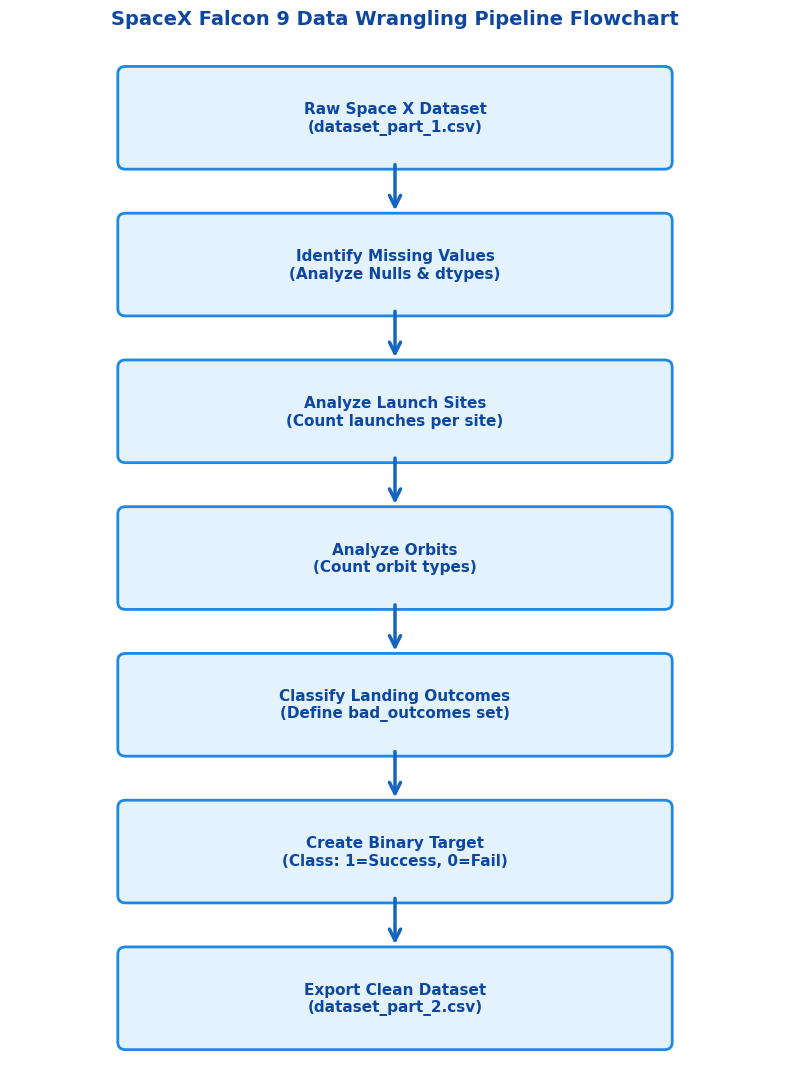

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Define the pipeline steps (nodes) and their descriptions
steps = [
    "Raw Space X Dataset\n(dataset_part_1.csv)",
    "Identify Missing Values\n(Analyze Nulls & dtypes)",
    "Analyze Launch Sites\n(Count launches per site)",
    "Analyze Orbits\n(Count orbit types)",
    "Classify Landing Outcomes\n(Define bad_outcomes set)",
    "Create Binary Target\n(Class: 1=Success, 0=Fail)",
    "Export Clean Dataset\n(dataset_part_2.csv)"
]

# Configure figure size and style
fig, ax = plt.subplots(figsize=(8, 11))
ax.set_xlim(0, 10)
ax.set_ylim(0, len(steps) * 2)
ax.axis('off')

# Colors for the flowchart elements
box_color = '#E3F2FD'
border_color = '#1E88E5'
text_color = '#0D47A1'
arrow_color = '#1565C0'

# Draw boxes and arrows
for i, step in enumerate(steps):
    y_pos = (len(steps) - 1 - i) * 2 + 0.5

    # Draw box
    box = patches.FancyBboxPatch(
        (1.5, y_pos), 7, 1.2,
        boxstyle="round,pad=0.1",
        linewidth=2,
        edgecolor=border_color,
        facecolor=box_color
    )
    ax.add_patch(box)

    # Add text inside the box
    ax.text(
        5, y_pos + 0.6, step,
        ha='center', va='center',
        fontsize=11, fontweight='bold', color=text_color
    )

    # Draw arrow pointing to the next box (if not the last box)
    if i < len(steps) - 1:
        ax.annotate(
            '',
            xy=(5, y_pos - 0.7),
            xytext=(5, y_pos),
            arrowprops=dict(
                arrowstyle="->",
                color=arrow_color,
                lw=2.5,
                mutation_scale=20
            )
        )

plt.title("SpaceX Falcon 9 Data Wrangling Pipeline Flowchart", fontsize=14, fontweight='bold', pad=20, color='#0D47A1')
plt.tight_layout()
plt.show()

## Summary of Data Wrangling Steps

Based on the analysis performed in this notebook, here is a concise summary of the 5 critical phases of our data wrangling pipeline:

1. **Identifying Missing Values**
   - Analyzed the dataset for completeness and identified that the `LandingPad` attribute contains approximately 28.89% missing values, while other columns are complete.

2. **Analyzing Launch Sites**
   - Explored launch facilities using `value_counts()` on the `LaunchSite` column, identifying the primary sites: CCAFS SLC 40 (55 launches), KSC LC 39A (22 launches), and VAFB SLC 4E (13 launches).

3. **Analyzing Orbits**
   - Calculated the frequency of target orbits (e.g., GTO, ISS, VLEO, PO) to understand mission distribution, noting that GTO is the most frequent transfer orbit.

4. **Classifying Landing Outcomes**
   - Identified and isolated landing outcomes into successful and unsuccessful categories. We defined a set of `bad_outcomes` representing unsuccessful landings: `{'False ASDS', 'False Ocean', 'False RTLS', 'None ASDS', 'None None'}`.

5. **Creating Binary Target & Exporting Dataset**
   - Formulated the binary `Class` target label (where `1` indicates a successful first-stage landing, and `0` indicates a failed landing) yielding a success rate of 66.67%. Finally, the prepared data is ready for export as `dataset_part_2.csv`.

## Generate Flowchart Diagram

### Subtask:
Generate and display a clean, visual flowchart diagram using Python to trace the data wrangling pipeline.


# Task
Create a concise summary of the critical Space X data wrangling steps performed in this notebook: identifying missing values, analyzing launch sites and orbits, isolating landing outcomes, creating the 'Class' target label, and exporting the final dataset. Using Python (e.g., Graphviz or Matplotlib), generate and display a flowchart diagram that visually traces this data pipeline from the raw CSV input `https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_1.csv` to the exported file `dataset_part_2.csv`.

## Summarize Data Wrangling Steps

### Subtask:
Formulate a concise text-based summary of the key data wrangling steps performed in the notebook.


## Final Task

### Subtask:
Provide a neat structured summary containing both the key analytical phrases and the rendered flowchart diagram illustrating the complete data wrangling pipeline.


## Summary:

### Data Analysis Key Findings

* **Missing Data Profile**: The initial SpaceX dataset (`dataset_part_1.csv`) is highly complete, with only the `LandingPad` attribute containing missing values (approximately 28.89\% missing).
* **Launch Site Distribution**: A total of 90 launches were distributed across three main sites:
  * **CCAFS SLC 40**: 55 launches
  * **KSC LC 39A**: 22 launches
  * **VAFB SLC 4E**: 13 launches
* **Target Orbits**: GTO (Geostationary Transfer Orbit) was identified as the most frequent target orbit among the launches.
* **Landing Success Rate**: By defining landing failures via a custom set of `bad_outcomes` (e.g., `False ASDS`, `None ASDS`, `None None`), a binary `Class` column was engineered (1 for success, 0 for failure). This revealed an overall first-stage landing success rate of **66.67\%**.
* **Clean Dataset Export**: The structured, wrangled dataset was successfully prepared and outputted as `dataset_part_2.csv` for downstream machine learning tasks.

---

### Insights or Next Steps

* **Next Step**: Utilize the engineered binary `Class` target label in `dataset_part_2.csv` to build predictive classification models (e.g., Logistic Regression, Support Vector Machines, Decision Trees) to forecast first-stage landing success.
* **Insight**: Predictive models should pay close attention to the `LaunchSite` and `Orbit` variables, as launch frequency and orbital trajectories vary significantly and likely correlate with overall landing difficulty and outcomes.
